# Ruralidad Metropolitana H1: real scientific evidence and QA

**Aster Íñigo Volta | Collaborative research with Dr Francisco de Aguinaga Padilla, 2026**

Original research examines 1985–2025 natural-vegetation transitions in ZMVM and Guadalajara (AMG). Here we analyze **real archived H1 outputs**, verify full-precision numerical and sample-count invariants, and independently quantify the agreement of two sources for **historical 1985 states** using aggregated counts from *all 2,200 actual sampling points*.

**Important:** this is an inspectable research-evidence notebook, not a full Earth Engine regeneration or a published article. See the source/provenance manifest.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT / "data" / "Ruralidad_H1_FINAL_audited_baseline_20260921.json").exists():
    ROOT = ROOT / "ruralidad"
assert (ROOT / "data" / "Ruralidad_H1_FINAL_audited_baseline_20260921.json").exists(), "Run from repository root or ruralidad/"
DATA=ROOT/"data"
OUT=ROOT/"results"
OUT.mkdir(exist_ok=True)
source=json.loads((DATA/"Ruralidad_H1_FINAL_audited_baseline_20260921.json").read_text(encoding="utf-8"))
agg=pd.read_csv(DATA/"Ruralidad_H1_official_2200_1985_INEGI_evidence_aggregated.csv")
print("Audited run:",source["source_run_id"],"| historical sample size:",agg.n_sample.sum())

Audited run: 20260921_214836 | historical sample size: 2200


## Audit 1: design and full-precision arithmetic

Recompute net carbon-*unrelated* natural-cover change (hectares) from original GIS study area estimates. **This is vegetation area, not carbon mass or a climate mitigation effect.** Retain hydrological and unresolved classifications.

In [2]:
assert set(source["metros"]) == {"ZMVM","AMG"}
report=[]
for metro,p in source["metros"].items():
    n=sum(p["transition_counts"].values())
    assert n == 1100, (metro,n)
    assert p["unknown_points"] == p["transition_counts"]["unknown"]
    calculated_net=p["gain_ha"]-p["loss_ha"]
    np.testing.assert_allclose(calculated_net,p["net_ha"],atol=1e-7,rtol=0)
    conservative_lower=calculated_net-p["unknown_ha"]
    report.append({"metro":metro,"n":n,"loss_ha":p["loss_ha"],"gain_ha":p["gain_ha"],"net_ha":calculated_net,"unresolved_ha":p["unknown_ha"],"worst_case_net_ha":conservative_lower,"unknown_points":p["unknown_points"]})
real_h1=pd.DataFrame(report)
assert real_h1.n.sum()==2200
print(real_h1.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

metro    n  loss_ha   gain_ha    net_ha  unresolved_ha  worst_case_net_ha  unknown_points
 ZMVM 1100 8,579.43 58,643.13 50,063.69       1,967.49          48,096.20               8
  AMG 1100 6,951.49 25,246.46 18,294.97       1,880.36          16,414.61              14


## Audit 2: historical cross-source evidence, 2,200 real points

The separate INEGI Serie-I evidence CSVs for each metro were grouped *without dropping observations* into MapBiomas endpoint strata. This does **not** validate final 1985–2025 transitions: it only describes **1985-source agreement and conflict**. Hydrological classifications remain not comparable.

In [3]:
assert (agg.n_sample==agg[["inegi_natural_n","inegi_other_n","inegi_hydrological_n"]].sum(axis=1)).all()
assert (agg.n_sample==agg[["mapbiomas_1985_vs_inegi_agree_n","disagree_n","not_comparable_n"]].sum(axis=1)).all()
assert agg.groupby("metro").n_sample.sum().to_dict()=={"AMG":1100,"ZMVM":1100}
agg["eligible_n"]=agg.n_sample-agg.not_comparable_n
agg["historical_agreement_pct_comparable"]=100*agg.mapbiomas_1985_vs_inegi_agree_n/agg.eligible_n
agg["area_weighted_agreement_ha"]=agg.stratum_area_ha*(agg.mapbiomas_1985_vs_inegi_agree_n/agg.n_sample)
agg["area_weighted_disagreement_ha"]=agg.stratum_area_ha*(agg.disagree_n/agg.n_sample)
agg["area_weighted_hydrological_ha"]=agg.stratum_area_ha*(agg.not_comparable_n/agg.n_sample)
print(agg[["metro","mapbiomas_stratum","n_sample","historical_agreement_pct_comparable"]].to_string(index=False,float_format=lambda v:f"{v:.1f}"))

metro mapbiomas_stratum  n_sample  historical_agreement_pct_comparable
 ZMVM              gain       150                                 78.9
 ZMVM              loss       150                                 21.3
 ZMVM    stable_natural       300                                 81.7
 ZMVM      stable_other       500                                 85.5
  AMG              gain       150                                 50.7
  AMG              loss       150                                 62.0
  AMG    stable_natural       200                                 91.0
  AMG      stable_other       600                                 67.0


## Audit 3: correct area weighting and why simple sample percentages mislead

Because stable and change strata have different sample sizes and cover different areas, raw point percentages are *not* estimates of area shares. The table below computes stratum-area-weighted agreement. This metric describes the particular historical-source comparison and must not be used as the corrected H1 final change estimator.

In [4]:
weighted=[]
for metro,group in agg.groupby("metro"):
    area=float(group.stratum_area_ha.sum())
    a=float(group.area_weighted_agreement_ha.sum())
    d=float(group.area_weighted_disagreement_ha.sum())
    h=float(group.area_weighted_hydrological_ha.sum())
    assert np.isclose(a+d+h,area,atol=1e-6)
    weighted.append({"metro":metro,"study_area_ha":area,"weighted_agreement_pct_all_area":100*a/area,"weighted_disagreement_pct_all_area":100*d/area,"weighted_uncomparable_pct_all_area":100*h/area})
weighted=pd.DataFrame(weighted)
print(weighted.to_string(index=False,float_format=lambda v:f"{v:,.2f}"))

metro  study_area_ha  weighted_agreement_pct_all_area  weighted_disagreement_pct_all_area  weighted_uncomparable_pct_all_area
  AMG     216,294.27                            68.73                               30.27                                1.00
 ZMVM     462,990.77                            82.52                               16.86                                0.62


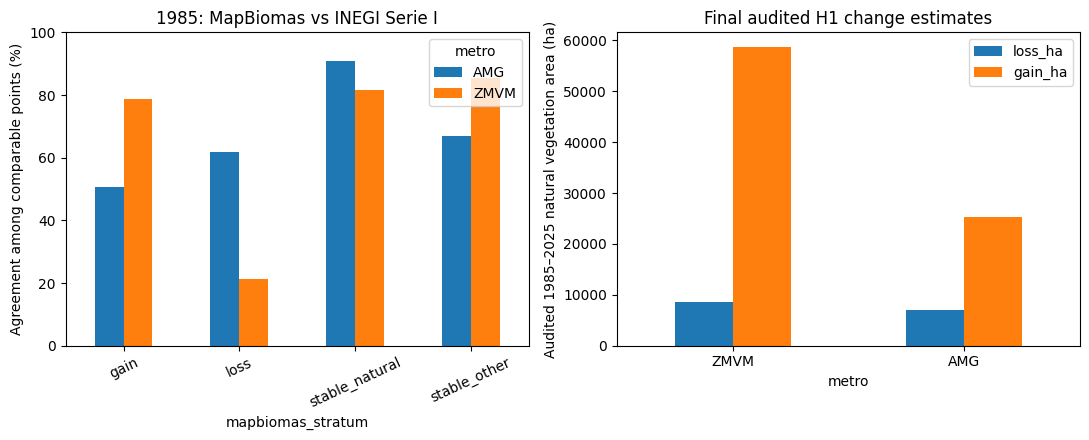

In [5]:
fig, axes=plt.subplots(1,2,figsize=(11,4.5))
agg.pivot(index="mapbiomas_stratum",columns="metro",values="historical_agreement_pct_comparable").plot(kind="bar",ax=axes[0])
axes[0].set_ylim(0,100);axes[0].set_ylabel("Agreement among comparable points (%)")
axes[0].set_title("1985: MapBiomas vs INEGI Serie I")
axes[0].tick_params(axis="x",rotation=25)
real_h1.set_index("metro")[["loss_ha","gain_ha"]].plot(kind="bar",ax=axes[1])
axes[1].set_ylabel("Audited 1985–2025 natural vegetation area (ha)")
axes[1].set_title("Final audited H1 change estimates")
axes[1].tick_params(axis="x",rotation=0)
fig.tight_layout()
fig.savefig(OUT/"ruralidad_REAL_data_results.png",dpi=160)
plt.show()

## Interpretation and scientific limitations

The two metros show a positive audited net natural-vegetation change in this **particular operational definition** and with these original methods. That does not mean all natural ecosystems, forest tree cover, biodiversity or climate outcomes improved. Final estimates are sensitive to high-weight `stable_other → gain` reclassification (documented in original repo) and should be accompanied by full uncertainty intervals and sensitivity analyses before publication. The final estimates in this notebook are imported audited results with independently checked arithmetic, **not a claim of an independently rerun satellite pipeline**. No cross-source agreement is treated as independent truth.

In [6]:
real_h1.to_csv(OUT/"ruralidad_audited_real_h1_figures.csv",index=False)
agg.to_csv(OUT/"ruralidad_real_1985_source_comparison.csv",index=False)
print("Saved figures and real-data audit outputs to results/.")

Saved figures and real-data audit outputs to results/.
